# Validating Gemini as a fact-checker on the LIAR benchmark

Before using Gemini as the reference fact-checker, we checked how it performs on **LIAR** (Wang, 2017):
12.8k short political statements labelled by PolitiFact on a 6-point scale. We use the official test split
(1,267 statements; download `test.tsv` from the LIAR dataset) and compare against the text-only
baselines of the original paper.

**Result:** 30.2% six-class accuracy on 1,245 valid predictions, above every text-only baseline in Wang (2017):
CNN 27.0%, SVM 25.5%, Bi-LSTM 23.3%, majority class 20.8%.

> **Note for readers.** This notebook is kept as it was run for the study. Two details matter when reading the result:
> the API call inside the loop uses `gemini-2.0-flash` **with Google Search grounding** (the model name set at the top is not
> the one used in the call), and 22 failed predictions are excluded. With search enabled the model may retrieve the PolitiFact
> verdict itself, so this is a sanity check of the setup rather than a like-for-like comparison with closed-book baselines.
> The model's self-reported confidence is uninformative here (92.8% when right vs. 92.3% when wrong).

# Import Dataset

In [ ]:
import pandas as pd

# Column names from README
columns = [
    'id',
    'label',
    'statement',
    'subject',
    'speaker',
    'job_title',
    'state_info',
    'party_affiliation',
    'barely_true_counts',
    'false_counts',
    'half_true_counts',
    'mostly_true_counts',
    'pants_on_fire_counts',
    'context'
]

# Load test set
df_test = pd.read_csv('test.tsv', sep='\t', header=None, names=columns)


(df_test.head())

           id       label                                          statement  \
0  11972.json        true  Building a wall on the U.S.-Mexico border will...   
1  11685.json       false  Wisconsin is on pace to double the number of l...   
2  11096.json       false  Says John McCain has done nothing to help the ...   
3   5209.json   half-true  Suzanne Bonamici supports a plan that will cut...   
4   9524.json  pants-fire  When asked by a reporter whether hes at the ce...   

                                             subject  \
0                                        immigration   
1                                               jobs   
2                    military,veterans,voting-record   
3  medicare,message-machine-2012,campaign-adverti...   
4  campaign-finance,legal-issues,campaign-adverti...   

                            speaker             job_title state_info  \
0                        rick-perry              Governor      Texas   
1                 katrina-shankland  S

In [ ]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1267 entries, 0 to 1266
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   id                    1267 non-null   object
 1   label                 1267 non-null   object
 2   statement             1267 non-null   object
 3   subject               1267 non-null   object
 4   speaker               1267 non-null   object
 5   job_title             942 non-null    object
 6   state_info            1005 non-null   object
 7   party_affiliation     1267 non-null   object
 8   barely_true_counts    1267 non-null   int64 
 9   false_counts          1267 non-null   int64 
 10  half_true_counts      1267 non-null   int64 
 11  mostly_true_counts    1267 non-null   int64 
 12  pants_on_fire_counts  1267 non-null   int64 
 13  context               1250 non-null   object
dtypes: int64(5), object(9)
memory usage: 138.7+ KB


# API Gemini

In [ ]:
import pandas as pd
import google.generativeai as genai
import os
from collections import Counter

# ============================================
# 1. CONFIGURE API
# ============================================
genai.configure(api_key=os.environ['GEMINI_API_KEY'])
model = genai.GenerativeModel('gemini-3.1-flash-lite')

# ============================================
# 2. LOAD LIAR TEST SET
# ============================================
columns = [
    'id', 'label', 'statement', 'subject', 'speaker',
    'job_title', 'state_info', 'party_affiliation',
    'barely_true_counts', 'false_counts', 'half_true_counts',
    'mostly_true_counts', 'pants_on_fire_counts', 'context'
]

df_test   = pd.read_csv('test.tsv', sep='\t', header=None, names=columns)
sample_df = df_test.copy()

print(f"Sample size: {len(sample_df)}")
print(f"\nLabel distribution:")
print(sample_df['label'].value_counts())

# ============================================
# 3. GEMINI API - TEXT ONLY
# Replicates paper's text-only baseline
# ============================================
results = []

for idx, row in sample_df.iterrows():
    statement  = row['statement']
    true_label = row['label']

    try:
        # TEXT ONLY - no metadata
        prompt = f"""You are a fact-checking system evaluating political statements.

Statement: {statement}

Classify the statement's truthfulness as one of:
- true: the statement is accurate and complete
- mostly-true: the statement is accurate but missing context
- half-true: the statement is partially accurate
- barely-true: the statement is mostly inaccurate
- false: the statement is not accurate
- pants-fire: the statement is completely false and ridiculous

Respond ONLY in this exact format:
Verdict: [true/mostly-true/half-true/barely-true/false/pants-fire]
Confidence: [0-100]%"""

        response      = genai.GenerativeModel('gemini-2.0-flash').generate_content(
    contents=prompt,
    tools=[{'google_search_retrieval': {}}]
)
        response_text = response.text.strip()

        verdict    = None
        confidence = None

        for line in response_text.split('\n'):
            line = line.strip()
            if line.startswith('Verdict:'):
                verdict = line.replace('Verdict:', '').strip().lower()
                verdict = verdict.replace('[', '').replace(']', '').strip()
            if line.startswith('Confidence:'):
                conf_str   = line.replace('Confidence:', '').strip()
                digits     = ''.join(filter(str.isdigit, conf_str))
                confidence = int(digits) if digits else 0

        valid_labels = ['true', 'mostly-true', 'half-true', 'barely-true', 'false', 'pants-fire']
        if verdict not in valid_labels:
            verdict = 'ERROR'

        results.append({
            'id':             row['id'],
            'statement':      statement,
            'true_label':     true_label,
            'gemini_verdict': verdict,
            'confidence':     confidence,
            'match':          true_label == verdict
        })

        if len(results) % 50 == 0:
            dist = Counter([r['gemini_verdict'] for r in results])
            print(f"Processed {len(results)}/600 | {dict(dist)}")

    except Exception as e:
        print(f"Error on idx {idx}: {e}")
        results.append({
            'id':             row['id'],
            'statement':      statement,
            'true_label':     true_label,
            'gemini_verdict': 'ERROR',
            'confidence':     0,
            'match':          False
        })

# ============================================
# 4. SAVE
# ============================================
results_df = pd.DataFrame(results)
results_df.to_csv('gemini_liar_text_only_results.csv', index=False)
print(f"\nSaved: gemini_liar_text_only_results.csv ({len(results_df)} observations)")
print(f"\nVerdict distribution:")
print(results_df['gemini_verdict'].value_counts())
print(f"\nTrue label distribution:")
print(results_df['true_label'].value_counts())

Sample size: 1267

Label distribution:
label
half-true      265
false          249
mostly-true    241
barely-true    212
true           208
pants-fire      92
Name: count, dtype: int64
Processed 50/600 | {'true': 11, 'false': 18, 'half-true': 12, 'mostly-true': 8, 'ERROR': 1}


ERROR:tornado.access:503 POST /v1beta/models/gemini-3.1-flash-lite:generateContent?%24alt=json%3Benum-encoding%3Dint (::1) 1727.79ms


Processed 100/600 | {'true': 16, 'false': 38, 'half-true': 24, 'mostly-true': 16, 'ERROR': 1, 'barely-true': 5}
Processed 150/600 | {'true': 27, 'false': 53, 'half-true': 33, 'mostly-true': 26, 'ERROR': 2, 'barely-true': 7, 'pants-fire': 2}
Processed 200/600 | {'true': 33, 'false': 70, 'half-true': 45, 'mostly-true': 35, 'ERROR': 3, 'barely-true': 11, 'pants-fire': 3}
Processed 250/600 | {'true': 37, 'false': 86, 'half-true': 57, 'mostly-true': 44, 'ERROR': 3, 'barely-true': 20, 'pants-fire': 3}
Processed 300/600 | {'true': 41, 'false': 103, 'half-true': 66, 'mostly-true': 57, 'ERROR': 5, 'barely-true': 24, 'pants-fire': 4}
Processed 350/600 | {'true': 51, 'false': 124, 'half-true': 73, 'mostly-true': 65, 'ERROR': 5, 'barely-true': 28, 'pants-fire': 4}
Processed 400/600 | {'true': 55, 'false': 148, 'half-true': 81, 'mostly-true': 77, 'ERROR': 6, 'barely-true': 29, 'pants-fire': 4}
Processed 450/600 | {'true': 65, 'false': 163, 'half-true': 96, 'mostly-true': 82, 'ERROR': 8, 'barely-tru

# Results

=== DATASET OVERVIEW ===
Total:  1267
Valid:  1245
Errors: 22

=== GEMINI TEXT-ONLY RESULTS ===
Accuracy:  0.3020 (30.20%)
Precision: 0.3210
Recall:    0.3020
F1-Score:  0.2847

Avg Confidence: 92.5%

--- PAPER BASELINES (text-only) ---
Majority:  20.8%
SVMs:      25.5%
Bi-LSTMs:  23.3%
CNNs:      27.0%
Gemini:    30.20%

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

        true       0.40      0.34      0.37       203
 mostly-true       0.29      0.29      0.29       240
   half-true       0.30      0.31      0.30       260
 barely-true       0.21      0.08      0.11       210
       false       0.27      0.53      0.36       241
  pants-fire       0.67      0.13      0.22        91

    accuracy                           0.30      1245
   macro avg       0.36      0.28      0.28      1245
weighted avg       0.32      0.30      0.28      1245

=== PER-LABEL PERFORMANCE ===
true            70/203 correct (34.48%) | Avg confidence: 93.4%
mostly-tr

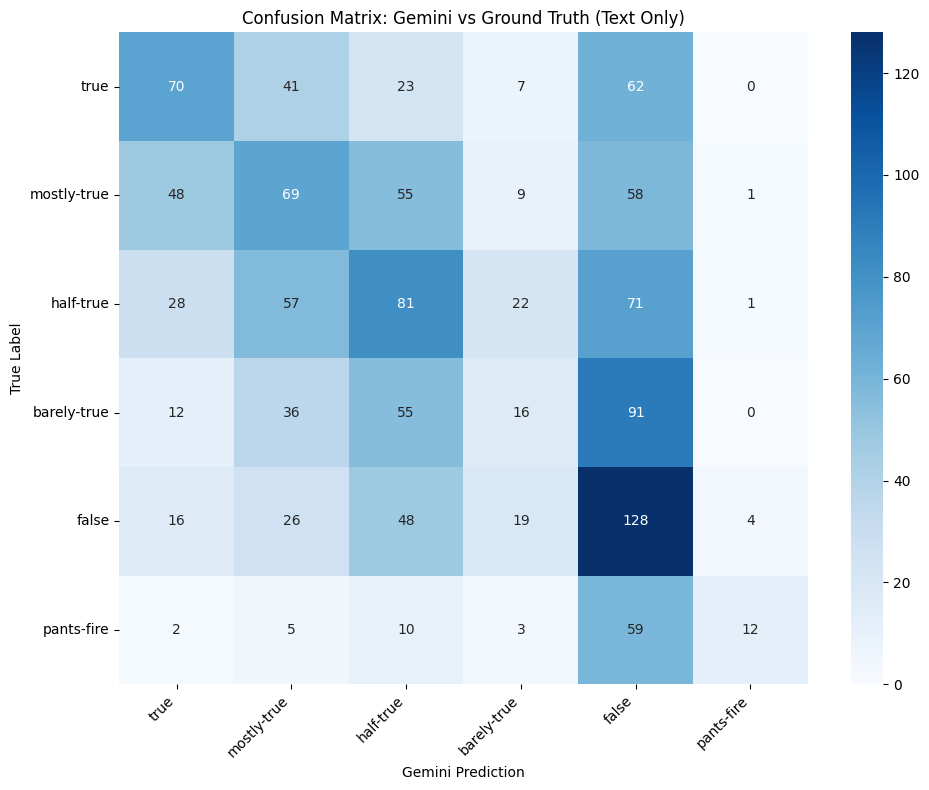


=== CONFIDENCE ANALYSIS ===
Avg confidence (correct):   92.8%
Avg confidence (incorrect): 92.3%
Difference:                 0.4%


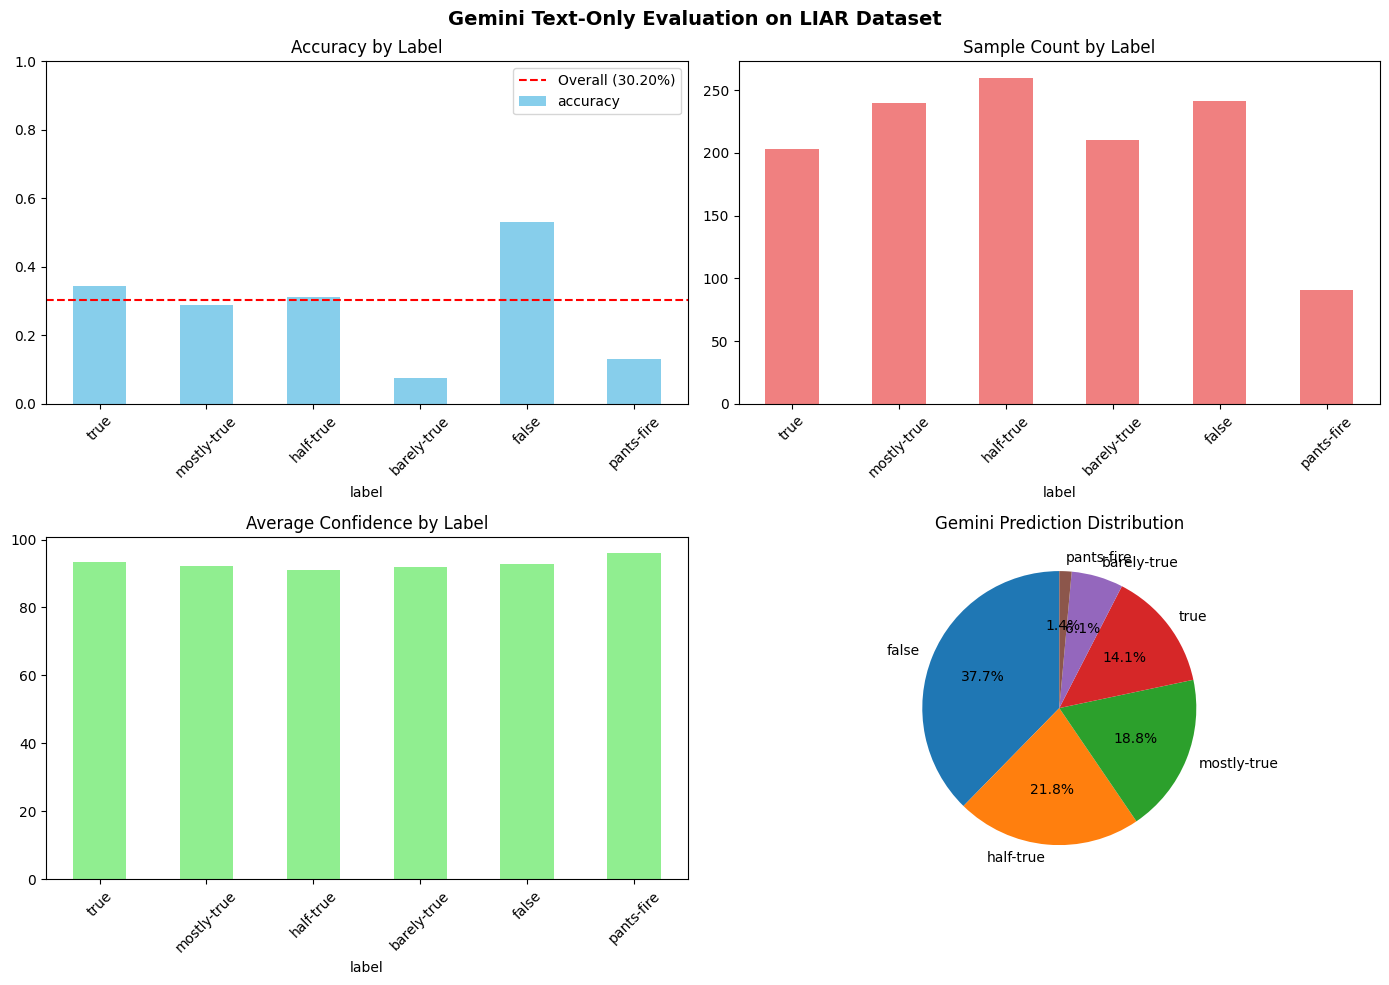

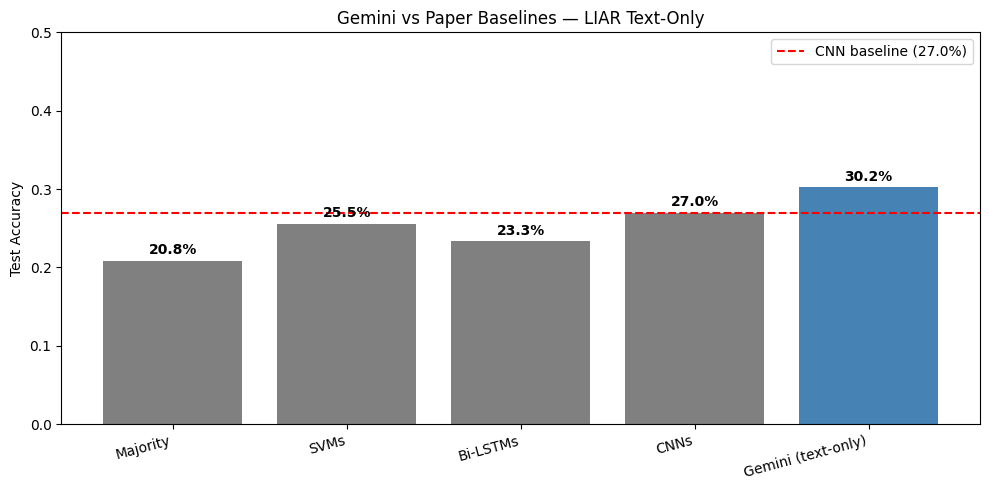


✅ COMPLETE!
✓ confusion_matrix_liar_text_only.png
✓ gemini_liar_text_only_analysis.png
✓ gemini_vs_baselines_liar.png
✓ gemini_liar_detailed_analysis.csv
✓ gemini_liar_summary.csv


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================
# 1. LOAD RESULTS
# ============================================
results_df = pd.read_csv('gemini_liar_text_only_results.csv')
clean_df   = results_df[results_df['gemini_verdict'] != 'ERROR'].copy()

print(f"=== DATASET OVERVIEW ===")
print(f"Total:  {len(results_df)}")
print(f"Valid:  {len(clean_df)}")
print(f"Errors: {len(results_df) - len(clean_df)}")

# ============================================
# 2. OVERALL METRICS
# ============================================
labels = ['true', 'mostly-true', 'half-true', 'barely-true', 'false', 'pants-fire']

accuracy  = accuracy_score(clean_df['true_label'], clean_df['gemini_verdict'])
precision = precision_score(clean_df['true_label'], clean_df['gemini_verdict'], average='weighted', zero_division=0, labels=labels)
recall    = recall_score(clean_df['true_label'], clean_df['gemini_verdict'], average='weighted', zero_division=0, labels=labels)
f1        = f1_score(clean_df['true_label'], clean_df['gemini_verdict'], average='weighted', zero_division=0, labels=labels)

print(f"""
=== GEMINI TEXT-ONLY RESULTS ===
Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)
Precision: {precision:.4f}
Recall:    {recall:.4f}
F1-Score:  {f1:.4f}

Avg Confidence: {clean_df['confidence'].mean():.1f}%

--- PAPER BASELINES (text-only) ---
Majority:  20.8%
SVMs:      25.5%
Bi-LSTMs:  23.3%
CNNs:      27.0%
Gemini:    {accuracy*100:.2f}%
""")

# ============================================
# 3. CLASSIFICATION REPORT
# ============================================
print("=== CLASSIFICATION REPORT ===")
print(classification_report(
    clean_df['true_label'],
    clean_df['gemini_verdict'],
    labels=labels,
    zero_division=0
))

# ============================================
# 4. PER-LABEL BREAKDOWN
# ============================================
print("=== PER-LABEL PERFORMANCE ===")
label_metrics = []
for label in labels:
    label_df = clean_df[clean_df['true_label'] == label]
    if len(label_df) == 0:
        continue
    label_acc     = accuracy_score(label_df['true_label'], label_df['gemini_verdict'])
    label_correct = (label_df['true_label'] == label_df['gemini_verdict']).sum()
    label_metrics.append({
        'label':          label,
        'count':          len(label_df),
        'correct':        label_correct,
        'accuracy':       label_acc,
        'avg_confidence': label_df['confidence'].mean()
    })
    print(f"{label:<15} {label_correct}/{len(label_df)} correct ({label_acc:.2%}) | Avg confidence: {label_df['confidence'].mean():.1f}%")

label_metrics_df = pd.DataFrame(label_metrics)

# ============================================
# 5. CONFUSION MATRIX
# ============================================
present_labels = [l for l in labels if l in clean_df['true_label'].values]
cm = confusion_matrix(clean_df['true_label'], clean_df['gemini_verdict'], labels=present_labels)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=present_labels, yticklabels=present_labels)
plt.title('Confusion Matrix: Gemini vs Ground Truth (Text Only)')
plt.ylabel('True Label')
plt.xlabel('Gemini Prediction')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('confusion_matrix_liar_text_only.png', dpi=300, bbox_inches='tight')
plt.show()

# ============================================
# 6. CONFIDENCE ANALYSIS
# ============================================
correct_mask         = clean_df['true_label'] == clean_df['gemini_verdict']
correct_confidence   = clean_df[correct_mask]['confidence'].mean()
incorrect_confidence = clean_df[~correct_mask]['confidence'].mean()

print(f"\n=== CONFIDENCE ANALYSIS ===")
print(f"Avg confidence (correct):   {correct_confidence:.1f}%")
print(f"Avg confidence (incorrect): {incorrect_confidence:.1f}%")
print(f"Difference:                 {correct_confidence - incorrect_confidence:.1f}%")

# ============================================
# 7. VISUALIZATIONS
# ============================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

label_metrics_df.set_index('label')['accuracy'].plot(kind='bar', ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Accuracy by Label')
axes[0, 0].set_ylim([0, 1])
axes[0, 0].axhline(y=accuracy, color='r', linestyle='--', label=f'Overall ({accuracy:.2%})')
axes[0, 0].legend()
axes[0, 0].tick_params(axis='x', rotation=45)

label_metrics_df.set_index('label')['count'].plot(kind='bar', ax=axes[0, 1], color='lightcoral')
axes[0, 1].set_title('Sample Count by Label')
axes[0, 1].tick_params(axis='x', rotation=45)

label_metrics_df.set_index('label')['avg_confidence'].plot(kind='bar', ax=axes[1, 0], color='lightgreen')
axes[1, 0].set_title('Average Confidence by Label')
axes[1, 0].tick_params(axis='x', rotation=45)

pred_dist = clean_df['gemini_verdict'].value_counts()
axes[1, 1].pie(pred_dist.values, labels=pred_dist.index, autopct='%1.1f%%', startangle=90)
axes[1, 1].set_title('Gemini Prediction Distribution')

plt.suptitle('Gemini Text-Only Evaluation on LIAR Dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('gemini_liar_text_only_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# ============================================
# 8. COMPARISON WITH PAPER BASELINES
# ============================================
comparison_df = pd.DataFrame({
    'Model':         ['Majority', 'SVMs', 'Bi-LSTMs', 'CNNs', 'Gemini (text-only)'],
    'Test Accuracy': [0.208,      0.255,  0.233,       0.270,  accuracy]
})

plt.figure(figsize=(10, 5))
colors = ['gray', 'gray', 'gray', 'gray', 'steelblue']
bars   = plt.bar(comparison_df['Model'], comparison_df['Test Accuracy'], color=colors)
plt.axhline(y=0.270, color='r', linestyle='--', label='CNN baseline (27.0%)')
plt.title('Gemini vs Paper Baselines — LIAR Text-Only')
plt.ylabel('Test Accuracy')
plt.ylim([0, 0.5])
plt.xticks(rotation=15, ha='right')
for bar, val in zip(bars, comparison_df['Test Accuracy']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.1%}', ha='center', va='bottom', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig('gemini_vs_baselines_liar.png', dpi=300, bbox_inches='tight')
plt.show()

# ============================================
# 9. SAVE
# ============================================
clean_df['correct'] = correct_mask
clean_df.to_csv('gemini_liar_detailed_analysis.csv', index=False)

summary_df = pd.DataFrame({
    'Metric': ['Total', 'Valid', 'Errors', 'Accuracy', 'Precision', 'Recall', 'F1', 'Avg Confidence'],
    'Value':  [len(results_df), len(clean_df), len(results_df) - len(clean_df),
               f"{accuracy*100:.2f}%", f"{precision:.4f}", f"{recall:.4f}",
               f"{f1:.4f}", f"{clean_df['confidence'].mean():.1f}%"]
})
summary_df.to_csv('gemini_liar_summary.csv', index=False)

print("\n✅ COMPLETE!")
print("✓ confusion_matrix_liar_text_only.png")
print("✓ gemini_liar_text_only_analysis.png")
print("✓ gemini_vs_baselines_liar.png")
print("✓ gemini_liar_detailed_analysis.csv")
print("✓ gemini_liar_summary.csv")